In [2]:
import os, sys, subprocess
from pathlib import Path

IS_COLAB = 'COLAB_RELEASE_TAG' in os.environ or 'google.colab' in sys.modules
USE_GOOGLE_DRIVE = True
RUN_NAME = '20261104_014733'
REUSE_RESULTS = True
RECOMPUTE_METRICS = False
TARGET_TRAIN_STEPS = 1000
N_PAIRS, N_VALIDATION, N_TEST = 5000, 100, 500
SEED = 42
EXPORT_ZIP = False

if IS_COLAB:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
        'diffusers==0.35.1', 'transformers==4.49.0', 'accelerate==1.10.1',
        'peft==0.17.1', 'safetensors==0.6.2', 'huggingface-hub==0.34.4',
        'datasets==3.6.0', 'torchmetrics==1.8.1', 'torch-fidelity==0.3.0',
        'numpy', 'pandas', 'pillow', 'matplotlib', 'python-docx'])
    NOTEBOOK_DIR = Path('/content/milestone3')
    if USE_GOOGLE_DRIVE:
        from google.colab import drive
        drive.mount('/content/drive')
        NOTEBOOK_DIR = Path('/content/drive/MyDrive/IE7615_Generative/Milestone3')
else:
    cwd = Path.cwd()
    NOTEBOOK_DIR = cwd if (cwd / 'Milestone_3.ipynb').exists() else cwd / 'submission/milestone 3'

ROOT = NOTEBOOK_DIR / 'artifacts/full_experiment'
RESULTS = NOTEBOOK_DIR / 'results' / RUN_NAME
TABLES, FIGURES = RESULTS / 'tables', RESULTS / 'figures'
for folder in [ROOT, TABLES, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)
if not REUSE_RESULTS and (ROOT / f'checkpoints/lora_{RUN_NAME}').exists():
    raise ValueError('Use a new RUN_NAME for a fresh experiment. Existing results are preserved.')
print('Notebook:', NOTEBOOK_DIR)
print('Experiment:', RUN_NAME, '| Reuse:', REUSE_RESULTS)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Notebook: /content/drive/MyDrive/IE7615_Generative/Milestone3
Experiment: 20261104_014733 | Reuse: True


In [3]:
import csv, json, time, random, hashlib, shutil, contextlib, textwrap, re, unicodedata, math, gc
import platform, importlib.metadata, zipfile
from collections import Counter, defaultdict
from datetime import datetime, timezone
from types import SimpleNamespace
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display, Markdown
from diffusers import (StableDiffusionPipeline, AutoencoderKL, UNet2DConditionModel,
    DDPMScheduler, DDIMScheduler, EulerDiscreteScheduler, DPMSolverMultistepScheduler)
from diffusers.utils import convert_state_dict_to_diffusers
from peft import LoraConfig, get_peft_model_state_dict
from transformers import CLIPTextModel, CLIPTokenizer, CLIPModel, CLIPProcessor

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.set_num_threads(8)
MODEL_ID = 'stable-diffusion-v1-5/stable-diffusion-v1-5'
PINNED_MODEL_REVISION = '451f4fe16113bff5a5d2269ed5ad43b0592e9a14'
SCORE_MODEL = 'openai/clip-vit-base-patch32'
SCORE_REVISION = '3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268'
plt.rcParams.update({'figure.dpi':110, 'savefig.dpi':180, 'font.size':10,
    'axes.spines.top':False, 'axes.spines.right':False})
COLORS = ['#245e87', '#ce7436', '#47876a', '#865d91', '#9a6c39', '#57737d']

def reject(message):
    raise ValueError(message)


def path(value):
    p = Path(value)
    return p if p.is_absolute() else ROOT / p


def relative(value):
    # Keep lexical project paths when outputs/checkpoints are symlinked to Colab Drive.
    p = Path(os.path.abspath(path(value)))
    try:
        return p.relative_to(ROOT).as_posix()
    except ValueError:
        return str(p)


def read_jsonl(filename):
    with path(filename).open(encoding='utf-8') as f:
        return [json.loads(line) for line in f if line.strip()]


def write_jsonl(filename, rows):
    p = path(filename)
    p.parent.mkdir(parents=True, exist_ok=True)
    with p.open('w', encoding='utf-8', newline='\n') as f:
        for row in rows:
            f.write(json.dumps(row, ensure_ascii=False) + '\n')


def write_json(filename, value):
    p = path(filename)
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')


def read_json(filename):
    return json.loads(path(filename).read_text(encoding='utf-8'))


def write_csv(filename, rows, fields):
    p = path(filename)
    p.parent.mkdir(parents=True, exist_ok=True)
    with p.open('w', newline='', encoding='utf-8') as f:
        writer = csv.DictWriter(f, fieldnames=fields, extrasaction='ignore')
        writer.writeheader()
        writer.writerows(rows)


def digest(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True).encode()).hexdigest()


def file_hash(filename):
    h = hashlib.sha256()
    with path(filename).open('rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()


def environment():
    packages = {}
    for name in ['torch', 'torchvision', 'diffusers', 'transformers', 'peft', 'torchmetrics', 'torch-fidelity']:
        try:
            packages[name] = importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:
            packages[name] = None
    return {'utc': datetime.now(timezone.utc).isoformat(), 'python': platform.python_version(),
            'platform': platform.platform(), 'packages': packages}


def fresh_dir(filename):
    p = path(filename)
    if p.exists() and any(p.iterdir()):
        raise FileExistsError(f'Output is not empty: {p}. Choose a new run/output directory.')
    p.mkdir(parents=True, exist_ok=True)
    return p


def choose_device(request='auto'):
    import torch
    result = ('cuda' if torch.cuda.is_available() else 'cpu') if request == 'auto' else request
    if result == 'cuda' and not torch.cuda.is_available():
        raise RuntimeError('CUDA is unavailable. Use --device cpu for a slow smoke run or move to a GPU host.')
    return result

In [4]:
def clean_caption(text):
    if not isinstance(text, str):
        return ''
    text = unicodedata.normalize('NFKC', text)
    text = ''.join(c if c.isprintable() else ' ' for c in text)
    return re.sub(r'\s+', ' ', text).strip()


def annotations(filename):
    p = path(filename)
    if p.suffix.lower() == '.json':
        data = json.loads(p.read_text(encoding='utf-8'))
        # Karpathy-format annotations. Original split labels are intentionally not reused.
        for row in data['images']:
            for sentence in row['sentences']:
                yield row['filename'], sentence.get('raw', ' '.join(sentence.get('tokens', [])))
    elif p.suffix.lower() in {'.token', '.tokens'}:
        for line in p.read_text(encoding='utf-8-sig').splitlines():
            if '\t' in line:
                name, caption = line.split('\t', 1)
                yield name.rsplit('#', 1)[0], caption
    else:
        with p.open(encoding='utf-8-sig', newline='') as f:
            first = f.readline()
            f.seek(0)
            delimiter = '|' if first.count('|') >= 2 else ( '\t' if '\t' in first else ',')
            reader = csv.DictReader(f, delimiter=delimiter, skipinitialspace=True)
            for row in reader:
                row = {k.strip(): v for k, v in row.items() if k}
                name = row.get('image_name', row.get('image', row.get('filename')))
                caption = row.get('comment', row.get('caption'))
                if name is None or caption is None:
                    raise ValueError('Expected image_name/comment or image/caption columns.')
                yield name.strip(), caption


def prepare(args):
    if not 1000 <= args.pairs <= 5000 and not args.allow_small:
        raise ValueError('The assignment requires 1000-5000 pairs; --allow-small is for tests only.')
    if args.pairs < 3 or args.captions_per_image < 1 or args.size < 32:
        raise ValueError('Need >=3 pairs, >=1 caption per image, and image size >=32.')
    output = fresh_dir(args.output)
    grouped = defaultdict(list)
    counts = Counter()
    for name, caption in annotations(args.captions):
        counts['raw_captions'] += 1
        caption = clean_caption(caption)
        if not caption or caption.casefold() in {'nan', 'none'}:
            counts['empty_captions'] += 1
            continue
        if caption in grouped[name]:
            counts['duplicate_captions'] += 1
            continue
        grouped[name].append(caption)
    rng = random.Random(args.seed)
    names = sorted(grouped)
    rng.shuffle(names)
    selected, seen, pairs = [], set(), 0
    root = path(args.images).resolve()
    for name in names:
        image_path = (root / name).resolve()
        if not image_path.is_relative_to(root):
            raise ValueError(f'Image path escapes input directory: {name}')
        try:
            with Image.open(image_path) as im:
                im = ImageOps.exif_transpose(im).convert('RGB')
                im.load()
                sha = hashlib.sha256(str(im.size).encode() + im.tobytes()).hexdigest()
                if sha in seen:
                    counts['duplicate_images'] += 1
                    continue
                seen.add(sha)
                size = list(im.size)
                resized = ImageOps.fit(im, (args.size, args.size), method=Image.Resampling.LANCZOS)
        except (OSError, ValueError, Image.DecompressionBombError):
            counts['missing_or_corrupt_images'] += 1
            continue
        captions = list(grouped[name])
        rng.shuffle(captions)
        captions = captions[:min(args.captions_per_image, args.pairs - pairs)]
        dest = output / 'images' / f'{sha}.png'
        dest.parent.mkdir(exist_ok=True)
        resized.save(dest)
        selected.append({'image_id': sha, 'image': relative(dest), 'source_name': name,
                         'original_size': size, 'captions': captions})
        pairs += len(captions)
        if pairs == args.pairs:
            break
    if pairs < args.pairs:
        raise ValueError(f'Only {pairs} valid pairs available, requested {args.pairs}. Use a new output directory on retry.')
    if len(selected) < 3:
        raise ValueError('Need at least three unique images for disjoint splits.')
    rng.shuffle(selected)
    n_eval = max(1, int(len(selected) * .1))
    splits = {'test': selected[:n_eval], 'val': selected[n_eval:2*n_eval], 'train': selected[2*n_eval:]}
    stats = {}
    for split, images in splits.items():
        rows = []
        for row in images:
            for i, caption in enumerate(row['captions']):
                rows.append({k: v for k, v in row.items() if k != 'captions'} |
                            {'id': f"{row['image_id']}_{i}", 'caption': caption, 'split': split})
        write_jsonl(output / f'{split}.jsonl', rows)
        stats[split] = {'pairs': len(rows), 'unique_images': len(images)}
    write_json(output / 'dataset_card.json', {
        'dataset': 'Flickr30k', 'status': 'processed', 'requested_pairs': args.pairs,
        'seed': args.seed, 'split_policy': 'custom seeded 80/10/10 by decoded RGB SHA256; not Karpathy benchmark',
        'size': args.size, 'pixel_storage': 'RGB uint8 PNG; training normalizes to [-1, 1]',
        'crop': 'EXIF transpose then aspect-preserving center crop', 'splits': stats,
        'encountered_filter_counts': dict(counts), 'annotation_sha256': file_hash(args.captions),
        'subset_selection': 'shuffled image names, validate until requested pair count is reached',
        'limitation': 'Exact duplicates removed. Near duplicates and pretraining overlap are not ruled out.'})
    print(json.dumps(stats, indent=2))

DATASET_ID = 'lmms-lab-encoder/flickr30k'
DATASET_REVISION = '765d117f3eec816f2bfdc2d73ebb50a6f77b86a4'
RAW_CANDIDATES = 5500
PROCESSED = ROOT / 'data/processed'

def download_flickr30k(raw, count=RAW_CANDIDATES):
    from datasets import load_dataset
    raw.mkdir(parents=True, exist_ok=True)
    (raw / 'images').mkdir(exist_ok=True)
    source = raw / 'source.json'
    if source.exists() and read_json(source).get('images') == count:
        return
    # Recreate the deterministic caption manifest on retry; completed PNGs are reused.
    stream = load_dataset(DATASET_ID, split='test', revision=DATASET_REVISION,
        streaming=True).shuffle(seed=SEED, buffer_size=2048)
    actual = 0
    with (raw / 'captions.csv').open('w', encoding='utf-8', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=['image','caption'])
        writer.writeheader()
        for i, record in enumerate(stream.take(count)):
            name = f'{i:06d}.png'
            if not (raw / 'images' / name).exists():
                record['image'].convert('RGB').save(raw / 'images' / name)
            captions = record['caption']
            for caption in [captions] if isinstance(captions,str) else captions:
                writer.writerow(dict(image=name,caption=caption))
            actual = i + 1
            if actual % 100 == 0:
                print(f'Downloaded {actual}/{count}', flush=True)
    if actual != count:
        raise ValueError(f'Only {actual} images returned')
    write_json(source, dict(dataset=DATASET_ID, revision=DATASET_REVISION,
        source_split='test', images=actual, seed=SEED, sampling='stream shuffle buffer=2048, then take N'))

if not (PROCESSED / 'dataset_card.json').exists():
    raw = ROOT / 'data/raw/flickr30k'
    download_flickr30k(raw)
    # Prepare into a temporary sibling so an interrupted preprocessing run can be retried.
    work = ROOT / 'data/preparing'
    if work.exists():
        assert work.resolve().parent == (ROOT / 'data').resolve()
        shutil.rmtree(work)
    prepare(SimpleNamespace(images=raw/'images', captions=raw/'captions.csv', output=work,
        pairs=N_PAIRS, captions_per_image=1, size=512, seed=SEED, allow_small=False))
    for split in ['train','val','test']:
        rows = read_jsonl(work / f'{split}.jsonl')
        for row in rows: row['image'] = row['image'].replace('data/preparing/', 'data/processed/')
        write_jsonl(work / f'{split}.jsonl', rows)
    work.replace(PROCESSED)

dataset_card = read_json(PROCESSED / 'dataset_card.json')
split_rows = {s:read_jsonl(PROCESSED / f'{s}.jsonl') for s in ['train','val','test']}
assert sum(map(len,split_rows.values())) == N_PAIRS, 'Dataset size changed; use the matching settings/data.'
image_sets = {s:{r['image_id'] for r in rows} for s,rows in split_rows.items()}
assert not any(image_sets[a] & image_sets[b] for a,b in [('train','val'),('train','test'),('val','test')])
for split, rows in split_rows.items():
    assert len({r['id'] for r in rows}) == len(rows)
    assert all(r['split'] == split and r['caption'].strip() and path(r['image']).exists() for r in rows)

def make_prompts(rows):
    selected = [dict(id=r['id'],prompt=r['caption'],image_id=r['image_id'],
        reference_image=r['image'],split=r['split']) for r in rows]
    random.Random(SEED).shuffle(selected)
    return selected

val_prompts, test_prompts = make_prompts(split_rows['val']), make_prompts(split_rows['test'])
assert N_VALIDATION <= len(val_prompts) and N_TEST <= len(test_prompts)
dataset_table = pd.DataFrame([dict(split=s,pairs=len(rows),unique_images=len(image_sets[s])) for s,rows in split_rows.items()])
dataset_table.to_csv(TABLES / 'dataset_split.csv', index=False)
display(dataset_table)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

Downloaded 100/5500
Downloaded 200/5500
Downloaded 300/5500
Downloaded 400/5500
Downloaded 500/5500
Downloaded 600/5500
Downloaded 700/5500
Downloaded 800/5500
Downloaded 900/5500
Downloaded 1000/5500
Downloaded 1100/5500
Downloaded 1200/5500
Downloaded 1300/5500
Downloaded 1400/5500
Downloaded 1500/5500
Downloaded 1600/5500
Downloaded 1700/5500
Downloaded 1800/5500
Downloaded 1900/5500
Downloaded 2000/5500
Downloaded 2100/5500
Downloaded 2200/5500
Downloaded 2300/5500
Downloaded 2400/5500
Downloaded 2500/5500
Downloaded 2600/5500
Downloaded 2700/5500
Downloaded 2800/5500
Downloaded 2900/5500
Downloaded 3000/5500
Downloaded 3100/5500
Downloaded 3200/5500
Downloaded 3300/5500
Downloaded 3400/5500
Downloaded 3500/5500
Downloaded 3600/5500
Downloaded 3700/5500
Downloaded 3800/5500
Downloaded 3900/5500
Downloaded 4000/5500
Downloaded 4100/5500
Downloaded 4200/5500
Downloaded 4300/5500
Downloaded 4400/5500
Downloaded 4500/5500
Downloaded 4600/5500
Downloaded 4700/5500
Downloaded 4800/5500
D

,split,pairs,unique_images
0,train,4000,4000
1,val,500,500
2,test,500,500


In [5]:
def load_pipeline(model_id=MODEL_ID, device='auto', revision=None, lora=None):
    device = choose_device(device)
    dtype = torch.float16 if device == 'cuda' else torch.float32
    pipe = StableDiffusionPipeline.from_pretrained(model_id, revision=revision or PINNED_MODEL_REVISION,
                                                  torch_dtype=dtype, use_safetensors=True)
    if lora:
        pipe.load_lora_weights(str(lora))
    pipe.to(device)
    pipe.enable_vae_slicing()
    pipe.set_progress_bar_config(disable=True)
    # Keep the pretrained safety checker and record its flags in run metadata.
    return pipe


def set_scheduler(pipe, original_config, name='ddim', spacing='leading'):
    classes = {'ddim': DDIMScheduler, 'euler': EulerDiscreteScheduler,
               'dpm': DPMSolverMultistepScheduler}
    if name not in classes or spacing not in {'leading', 'trailing', 'linspace'}:
        raise ValueError('Unsupported scheduler or timestep spacing')
    # Retain pretrained beta_start/beta_end/beta_schedule/prediction_type.
    # Changing these blindly would mismatch the denoiser's training distribution.
    pipe.scheduler = classes[name].from_config(original_config, timestep_spacing=spacing)


def encode_clip(tokenizer, encoder, texts, embedding='clip_last'):
    tokens = tokenizer(texts, padding='max_length', max_length=tokenizer.model_max_length,
                       truncation=True, return_tensors='pt')
    device = next(encoder.parameters()).device
    ids = tokens.input_ids.to(device)
    mask = tokens.attention_mask.to(device) if getattr(encoder.config, 'use_attention_mask', False) else None
    if embedding == 'clip_last':
        return encoder(ids, attention_mask=mask)[0]
    if embedding == 'clip_penultimate':
        hidden = encoder(ids, attention_mask=mask, output_hidden_states=True).hidden_states[-2]
        return encoder.text_model.final_layer_norm(hidden)
    raise ValueError(f'Unsupported embedding: {embedding}')

def json_config(config):
    # JSON has no infinity; DPM-Solver's default lambda_min_clipped is -inf. Keep it as text.
    return {k: str(v) if isinstance(v, float) and not math.isfinite(v) else v for k, v in config.items()}


def previous_run(output, prompts, settings, model_id, revision=None, lora=None):
    """Return the run identity and any saved run.json, refusing an output that holds a different run."""
    identity = {'model_id': model_id, 'revision': revision, 'lora': relative(lora) if lora else None,
                'settings': settings, 'prompt_sha256': digest(prompts), 'prompt_count': len(prompts)}
    if lora:
        identity['lora_files_sha256'] = {p.name: file_hash(p) for p in path(lora).glob('*.safetensors')}
    out = path(output)
    if not (out / 'run.json').exists():
        return identity, None
    previous = read_json(out / 'run.json')
    changed = [k for k, v in identity.items() if previous.get(k) != v]
    if changed:
        raise FileExistsError(f'{out} holds a different run ({", ".join(changed)} differ). Choose a new output directory.')
    return identity, previous


def generate_run(pipe, prompts, output, settings, model_id, revision=None, lora=None,
                 original_scheduler=None):
    if not prompts or len({r['id'] for r in prompts}) != len(prompts):
        raise ValueError('Prompt list must be nonempty with unique ids.')
    if settings['steps'] < 1 or settings['guidance'] < 1:
        raise ValueError('steps must be positive; guidance >=1 (1 means conditional without CFG amplification).')
    if any(settings[k] < 64 or settings[k] % 8 for k in ('width','height')):
        raise ValueError('Resolution must be >=64 and divisible by 8.')
    identity, previous = previous_run(output, prompts, settings, model_id, revision, lora)
    out, records, resumed = path(output), [], []
    if previous:
        # Rerunning the same command continues the run; a different configuration is never mixed in.
        if previous['status'] == 'complete':
            print(f'Already complete, skipping: {relative(out)}', flush=True)
            return read_jsonl(out / 'manifest.jsonl')
        if (out / 'manifest.jsonl').exists():
            records = read_jsonl(out / 'manifest.jsonl')
        if [r['id'] for r in records] != [r['id'] for r in prompts[:len(records)]]:
            raise ValueError(f'{out}/manifest.jsonl does not match the prompt order. Choose a new output directory.')
        resumed = previous.get('resumed_at_image', []) + [len(records)]
        print(f'Resuming {relative(out)} at image {len(records)+1}/{len(prompts)}', flush=True)
    else:
        fresh_dir(out)
    base = dict(original_scheduler or pipe.scheduler.config)
    set_scheduler(pipe, base, settings['scheduler'], settings['spacing'])
    metadata = {'status': 'running', 'kind': 'inference', **identity,
                'resolved_text_encoder_revision': getattr(pipe.text_encoder.config, '_commit_hash', None),
                'environment': environment(), 'scheduler_config': json_config(pipe.scheduler.config),
                'safety_checker_enabled': pipe.safety_checker is not None,
                'device': str(pipe.device), 'dtype': str(pipe.unet.dtype)}
    if resumed:
        metadata['resumed_at_image'] = resumed
    write_json(out / 'run.json', metadata)
    with torch.inference_mode():
        for i in range(len(records), len(prompts)):
            row = prompts[i]
            seed = settings['seed'] + i
            # CPU generator makes the initial random latent reproducible across devices.
            generator = torch.Generator(device='cpu').manual_seed(seed)
            positive = encode_clip(pipe.tokenizer, pipe.text_encoder, [row['prompt']], settings['embedding'])
            negative = encode_clip(pipe.tokenizer, pipe.text_encoder, [''], settings['embedding'])
            started = time.perf_counter()
            result = pipe(prompt_embeds=positive, negative_prompt_embeds=negative,
                          guidance_scale=settings['guidance'], num_inference_steps=settings['steps'],
                          height=settings['height'], width=settings['width'], generator=generator)
            if pipe.device.type == 'cuda':
                torch.cuda.synchronize()
            elapsed = time.perf_counter() - started
            name = f'{i:05d}.png'
            result.images[0].save(out / name)
            record = dict(row, image=relative(out / name), seed=seed, seconds=elapsed,
                          token_count=len(pipe.tokenizer(row['prompt']).input_ids),
                          safety_flag=(bool(result.nsfw_content_detected[0])
                                       if result.nsfw_content_detected is not None else None))
            records.append(record)
            write_jsonl(out / 'manifest.jsonl', records)
            print(f"{i+1}/{len(prompts)} {row['id']} {elapsed:.2f}s", flush=True)
    # Set explicitly so the record is right even when a resumed run had no images left.
    pipe.scheduler.set_timesteps(settings['steps'])
    metadata.update(status='complete', completed=len(records), total_inference_seconds=sum(r['seconds'] for r in records),
                    timesteps=[float(t) for t in pipe.scheduler.timesteps])
    write_json(out / 'run.json', metadata)
    return records

def complete_generation(output, prompts, settings, lora=None):
    identity, previous = previous_run(output, prompts, settings, MODEL_ID, None, lora)
    if previous is None:
        return False
    manifest = path(output) / 'manifest.jsonl'
    records = read_jsonl(manifest) if manifest.exists() else []
    if [r['id'] for r in records] != [r['id'] for r in prompts[:len(records)]]:
        raise ValueError(f'Prompt order mismatch: {output}')
    for i, row in enumerate(records):
        if (row['prompt'] != prompts[i]['prompt'] or row['seed'] != settings['seed'] + i
                or not path(row['image']).is_file()):
            raise ValueError(f'Incomplete or inconsistent cached image {output}/{i}')
    return previous.get('status') == 'complete' and len(records) == len(prompts)

def ensure_generation(output, prompts, settings, lora=None):
    if complete_generation(output, prompts, settings, lora):
        print('Reused:', output)
        return read_jsonl(path(output) / 'manifest.jsonl')
    pipe = load_pipeline(MODEL_ID, DEVICE, lora=path(lora) if lora else None)
    try:
        return generate_run(pipe, prompts, output, settings, MODEL_ID, lora=lora)
    finally:
        del pipe
        gc.collect()
        if DEVICE == 'cuda': torch.cuda.empty_cache()

In [6]:
IDENTITY = ['model','revision','rank','lr','seed','batch_size','accumulation','dropout','resolution','val_batches']

class CaptionDataset(Dataset):
    def __init__(self, rows, resolution=512):
        self.rows = rows
        self.resolution = resolution

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        with Image.open(path(row['image'])) as image:
            image = ImageOps.fit(image.convert('RGB'), (self.resolution,self.resolution), method=Image.Resampling.LANCZOS)
            image = np.asarray(image, dtype=np.float32).copy() / 127.5 - 1.0
        return torch.from_numpy(image).permute(2,0,1), row['caption']


def save_lora(unet, out):
    out.mkdir(parents=True, exist_ok=True)
    state = convert_state_dict_to_diffusers(get_peft_model_state_dict(unet))
    StableDiffusionPipeline.save_lora_weights(out, unet_lora_layers=state, safe_serialization=True)


def latest_state(out):
    states = sorted(out.glob('step-*/training_state.pt'), key=lambda f: int(f.parent.name.split('-')[1]))
    return states[-1] if states else None


def copy_best(out, step, val):
    best = out/'best'
    if best.is_dir():
        shutil.rmtree(best)
    shutil.copytree(out/f'step-{step}', best, ignore=shutil.ignore_patterns('training_state.pt*'))
    write_json(best/'selection.json', {'step':step,'val_loss':val})


def target_for(scheduler, latents, noise, times):
    mode = scheduler.config.prediction_type
    if mode == 'epsilon':
        return noise
    if mode == 'v_prediction':
        return scheduler.get_velocity(latents, noise, times)
    raise ValueError(f'Unsupported prediction type: {mode}')

def train_lora(a):
    train_rows, val_rows = read_jsonl(a.train), read_jsonl(a.val)
    if not train_rows or not val_rows:
        reject('Train and validation sets must be nonempty.')
    if any(r['split'] != 'train' for r in train_rows) or any(r['split'] != 'val' for r in val_rows):
        reject('Use train and val manifests with the correct split labels.')
    if {r['image_id'] for r in train_rows} & {r['image_id'] for r in val_rows}:
        reject('Train/validation image leakage detected.')
    out = path(a.output)
    data_hashes = {'train_sha256':file_hash(a.train),'val_sha256':file_hash(a.val)}
    previous = read_json(out/'training.json') if (out/'training.json').exists() else None
    if previous:
        if a.resume:
            reject(f'{out} already holds a run. Rerun without --resume to continue it, or choose a new --output.')
        changed = ([k for k in IDENTITY if previous['args'][k] != getattr(a,k)] +
                   [k for k,v in data_hashes.items() if previous[k] != v])
        if changed:
            raise FileExistsError(f'{out} holds a different training run ({", ".join(changed)} differ). Choose a new --output.')
        if previous['status'] == 'complete' and previous['optimizer_steps'] == a.steps:
            print(f'Already trained to step {a.steps}, skipping: {relative(out)}')
            return
    else:
        fresh_dir(out)
    resume = path(a.resume) if a.resume else latest_state(out) if previous else None
    device = choose_device(a.device)
    random.seed(a.seed)
    np.random.seed(a.seed)
    torch.manual_seed(a.seed)
    if device == 'cuda':
        torch.cuda.manual_seed_all(a.seed)
    dtype = torch.float16 if device == 'cuda' else torch.float32
    pretrained = dict(revision=a.revision or PINNED_MODEL_REVISION, use_safetensors=True)
    tokenizer = CLIPTokenizer.from_pretrained(a.model, subfolder='tokenizer', revision=a.revision or PINNED_MODEL_REVISION)
    text_encoder = CLIPTextModel.from_pretrained(a.model, subfolder='text_encoder', **pretrained).to(device, dtype=dtype).eval()
    vae = AutoencoderKL.from_pretrained(a.model, subfolder='vae', **pretrained).to(device).eval()
    unet = UNet2DConditionModel.from_pretrained(a.model, subfolder='unet', **pretrained).to(device, dtype=dtype)
    scheduler = DDPMScheduler.from_pretrained(a.model, subfolder='scheduler', revision=a.revision or PINNED_MODEL_REVISION)
    for module in (text_encoder, vae, unet):
        module.requires_grad_(False)
    unet.add_adapter(LoraConfig(r=a.rank, lora_alpha=a.rank, init_lora_weights='gaussian',
                               target_modules=['to_q','to_k','to_v','to_out.0']))
    trainable = [param for param in unet.parameters() if param.requires_grad]
    for param in trainable:
        param.data = param.data.float()
    unet.enable_gradient_checkpointing()
    optimizer = torch.optim.AdamW(trainable, lr=a.lr)
    scaler = torch.amp.GradScaler('cuda', enabled=device == 'cuda')
    training_data = CaptionDataset(train_rows, a.resolution)
    validation = DataLoader(CaptionDataset(val_rows,a.resolution), batch_size=a.batch_size, shuffle=False, num_workers=0)
    info = {'status':'running','kind':'lora_training','args':vars(a), 'environment':environment(),
            **data_hashes,
            'trainable_parameters':sum(x.numel() for x in trainable),
            'frozen_components':['VAE','CLIP','base UNet'], 'prediction_type':scheduler.config.prediction_type,
            'checkpoint_policy':'best fixed-validation denoising loss; periodic optimizer/RNG states; '
                                'rerunning continues in place from the latest state, --resume branches into a new output',
            'sampling':'independent seeded mini-batches per optimizer step, without replacement within each step'}

    def loss_batch(images, captions, drop=False):
        images = images.to(device, dtype=torch.float32)
        with torch.no_grad():
            latents = vae.encode(images).latent_dist.sample() * vae.config.scaling_factor
            latents = latents.to(dtype)
            texts = ['' if drop and random.random()<a.dropout else caption for caption in captions]
            hidden = encode_clip(tokenizer, text_encoder, texts)
            noise = torch.randn_like(latents)
            times = torch.randint(0, scheduler.config.num_train_timesteps, (len(images),), device=device)
            noisy = scheduler.add_noise(latents, noise, times)
            target = target_for(scheduler, latents, noise, times)
        context = torch.autocast('cuda', dtype=torch.float16) if device == 'cuda' else contextlib.nullcontext()
        with context:
            prediction = unet(noisy, times, encoder_hidden_states=hidden).sample
            return F.mse_loss(prediction.float(), target.float())

    def validate():
        unet.eval()
        # Fixed validation noise, while restoring the training RNG afterwards.
        with torch.random.fork_rng(devices=[torch.cuda.current_device()] if device == 'cuda' else []):
            torch.manual_seed(a.seed + 10000)
            losses = []
            with torch.no_grad():
                for i, (images, captions) in enumerate(validation):
                    if i >= a.val_batches:
                        break
                    losses.append(float(loss_batch(images, captions)))
        unet.train()
        return sum(losses)/len(losses)

    best, best_step, start_step = float('inf'), None, 0
    if resume:
        from peft import set_peft_model_state_dict
        print(f'Resuming from {relative(resume)}', flush=True)
        state = torch.load(resume,map_location='cpu',weights_only=True)
        for key in IDENTITY:
            if state['args'][key] != getattr(a,key):
                raise ValueError(f'Resume configuration differs in {key}')
        if state['train_sha256'] != info['train_sha256'] or state['val_sha256'] != info['val_sha256']:
            raise ValueError('Resume dataset manifests differ')
        set_peft_model_state_dict(unet,state['adapter'])
        optimizer.load_state_dict(state['optimizer'])
        scaler.load_state_dict(state['scaler'])
        torch.set_rng_state(state['torch_rng'])
        random.setstate(state['python_rng'])
        if device == 'cuda' and state['cuda_rng']:
            torch.cuda.set_rng_state_all(state['cuda_rng'])
        start_step, best, best_step = state['step'], state['best'], state.get('best_step')
        # In place, a state saved at the final step only needs the completion record below.
        if a.steps < start_step or (a.resume and a.steps == start_step):
            raise ValueError('--steps must exceed the resumed optimizer step')
        if a.resume:
            # Preserve the best adapter when later resumed steps do not improve it.
            previous_best = resume.parent.parent/'best'
            if previous_best.is_dir():
                shutil.copytree(previous_best,out/'best')
        elif best_step is not None:
            # An interruption after saving the state but before refreshing best/ leaves best/ stale.
            selected = out/'best'/'selection.json'
            if not selected.exists() or read_json(selected)['step'] != best_step:
                copy_best(out, best_step, best)
    # In place, the log and record continue the same chain; --resume starts a new segment.
    info['start_step'] = previous.get('start_step', 0) if previous else start_step
    if previous and resume:
        info['resumed_at_step'] = previous.get('resumed_at_step', []) + [start_step]
    write_json(out/'training.json', info)
    log, kept = out/'training_log.csv', []
    if previous and log.exists():
        with log.open(newline='', encoding='utf-8') as f:
            kept = [row for row in csv.DictReader(f) if int(row['step']) <= start_step]
    unet.train()
    with log.open('w', newline='', encoding='utf-8') as f:
        writer = csv.DictWriter(f, fieldnames=['step','train_loss','val_loss','lr','seconds','effective_batch'])
        writer.writeheader()
        writer.writerows(kept)
        for step in range(start_step+1, a.steps+1):
            started = time.perf_counter()
            optimizer.zero_grad(set_to_none=True)
            loss_sum = 0.
            batch_rng = np.random.default_rng(a.seed + step)
            count = a.batch_size*a.accumulation
            indices = batch_rng.choice(len(training_data),size=count,replace=count>len(training_data))
            for micro in range(a.accumulation):
                batch = [training_data[int(i)] for i in indices[micro*a.batch_size:(micro+1)*a.batch_size]]
                images = torch.stack([item[0] for item in batch])
                captions = [item[1] for item in batch]
                loss = loss_batch(images, captions, drop=True)
                if not torch.isfinite(loss):
                    raise RuntimeError('Nonfinite loss. Inspect inputs or use float32.')
                loss_sum += float(loss.detach())
                scaler.scale(loss/a.accumulation).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(trainable, 1.0)
            scaler.step(optimizer)
            scaler.update()
            val = None
            if step % a.save_every == 0 or step == a.steps:
                val = validate()
                save_lora(unet, out/f'step-{step}')
                if val < best:
                    best, best_step = val, step
                checkpoint = {'step':step,'best':best,'best_step':best_step,'args':vars(a),
                              'train_sha256':info['train_sha256'],'val_sha256':info['val_sha256'],
                              'adapter':get_peft_model_state_dict(unet), 'optimizer':optimizer.state_dict(),
                              'scaler':scaler.state_dict(),'torch_rng':torch.get_rng_state(),
                              'cuda_rng':torch.cuda.get_rng_state_all() if device=='cuda' else [],
                              'python_rng':random.getstate()}
                temporary = out/f'step-{step}'/'training_state.pt.partial'
                torch.save(checkpoint,temporary)
                temporary.replace(temporary.with_suffix(''))
                if best_step == step:
                    copy_best(out, step, val)
            writer.writerow({'step':step,'train_loss':loss_sum/a.accumulation,'val_loss':val,
                             'lr':a.lr,'seconds':time.perf_counter()-started,
                             'effective_batch':a.batch_size*a.accumulation})
            f.flush()
            print(f'step={step} loss={loss_sum/a.accumulation:.6f} val={val}', flush=True)
    info.update(status='complete', optimizer_steps=a.steps, best_validation_loss=best)
    write_json(out/'training.json', info)

tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

text_encoder/model.safetensors:   0%|          | 0.00/492M [00:00<?, ?B/s]

... (3 outputs left out)

unet/diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

scheduler_config.json:   0%|          | 0.00/308 [00:00<?, ?B/s]

step=1 loss=0.360254 val=None
step=2 loss=0.160842 val=None
step=3 loss=0.243407 val=None
step=4 loss=0.190725 val=None
step=5 loss=0.121551 val=None
step=6 loss=0.120800 val=None
step=7 loss=0.294273 val=None
step=8 loss=0.053956 val=None
step=9 loss=0.220070 val=None
step=10 loss=0.181483 val=None
step=11 loss=0.083190 val=None
step=12 loss=0.248001 val=None
step=13 loss=0.076578 val=None
step=14 loss=0.237421 val=None
step=15 loss=0.285396 val=None
step=16 loss=0.128634 val=None
step=17 loss=0.221945 val=None
step=18 loss=0.274290 val=None
step=19 loss=0.155540 val=None
step=20 loss=0.121767 val=None
step=21 loss=0.173925 val=None
step=22 loss=0.322128 val=None
step=23 loss=0.355436 val=None
step=24 loss=0.341077 val=None
step=25 loss=0.170901 val=None
step=26 loss=0.317788 val=None
step=27 loss=0.148362 val=None
step=28 loss=0.107070 val=None
step=29 loss=0.158835 val=None
step=30 loss=0.236531 val=None
step=31 loss=0.147176 val=None
step=32 loss=0.305140 val=None
step=33 loss=0.13

,optimizer_steps,training_images,sample_presentations,best_step,best_val_mse,logged_minutes
0,1000,4000,4000,1000,0.0872,46.2476


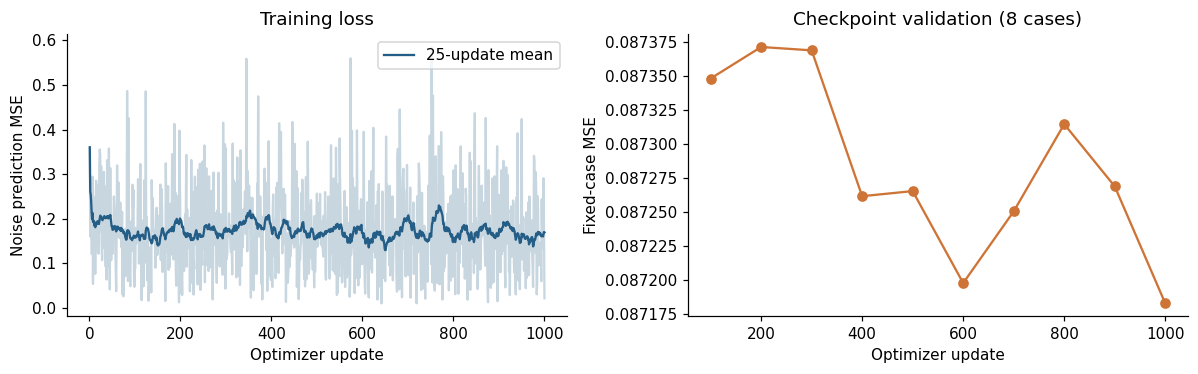

In [7]:
TRAIN = ROOT / f'checkpoints/lora_{RUN_NAME}'
train_args = SimpleNamespace(train='data/processed/train.jsonl',val='data/processed/val.jsonl',
    output=f'checkpoints/lora_{RUN_NAME}',model=MODEL_ID,revision=None,device=DEVICE,
    steps=TARGET_TRAIN_STEPS,batch_size=1,accumulation=4,rank=4,lr=1e-4,dropout=.1,
    seed=SEED,save_every=100,val_batches=8,resolution=512,resume=None)
train_lora(train_args)
training_info = read_json(TRAIN / 'training.json')
train_df = pd.read_csv(TRAIN / 'training_log.csv')
assert train_df.step.tolist() == list(range(1,TARGET_TRAIN_STEPS+1))
assert np.isfinite(train_df.train_loss).all()
best_info = read_json(TRAIN / 'best/selection.json')
assert (TRAIN / 'best/pytorch_lora_weights.safetensors').exists()
train_df.to_csv(TABLES / 'training_log.csv', index=False)
display(pd.DataFrame([dict(optimizer_steps=training_info['optimizer_steps'],
    training_images=len(split_rows['train']),sample_presentations=int(train_df.effective_batch.sum()),
    best_step=best_info['step'],best_val_mse=best_info['val_loss'],
    logged_minutes=train_df.seconds.sum()/60)]).round(4))
fig, axes = plt.subplots(1,2,figsize=(11,3.5))
axes[0].plot(train_df.step,train_df.train_loss,alpha=.25,color=COLORS[0])
axes[0].plot(train_df.step,train_df.train_loss.rolling(25,min_periods=1).mean(),color=COLORS[0],label='25-update mean')
axes[0].set(xlabel='Optimizer update',ylabel='Noise prediction MSE',title='Training loss')
axes[0].legend()
v = train_df.dropna(subset=['val_loss'])
axes[1].plot(v.step,v.val_loss,'o-',color=COLORS[1])
axes[1].set(xlabel='Optimizer update',ylabel='Fixed-case MSE',title='Checkpoint validation (8 cases)')
fig.tight_layout()
fig.savefig(FIGURES / 'training_loss.png')
plt.show()

In [8]:
BASE = dict(guidance=7.5,steps=30,scheduler='ddim',spacing='leading',embedding='clip_last',
    seed=SEED,height=512,width=512)
EXPERIMENTS = [dict(name='baseline'),dict(name='cfg1',guidance=1.),dict(name='cfg3',guidance=3.),
    dict(name='cfg5',guidance=5.),dict(name='cfg10',guidance=10.),dict(name='cfg12',guidance=12.),
    dict(name='steps20',steps=20),dict(name='steps50',steps=50),dict(name='euler',scheduler='euler'),
    dict(name='dpm',scheduler='dpm'),dict(name='trailing',spacing='trailing'),
    dict(name='clip_penultimate',embedding='clip_penultimate')]
SWEEP = ROOT / f'outputs/sweeps/validation_{RUN_NAME}'
TEST = ROOT / f'outputs/test/{RUN_NAME}'
LORA = f'checkpoints/lora_{RUN_NAME}/best'

# Preserve the original demonstration stages when their prompt configuration is present.
demo_file = ROOT / 'configs/prompts.jsonl'
if demo_file.exists():
    demo_prompts = read_jsonl(demo_file)
    for stage,limit,lora in [('stage1',5,None),('stage2',10,None),('lora_early',10,LORA)]:
        ensure_generation(f'outputs/runs/{stage}_{RUN_NAME}',demo_prompts[:limit],BASE,lora)

for experiment in EXPERIMENTS:
    settings = BASE | {k:v for k,v in experiment.items() if k != 'name'}
    ensure_generation(SWEEP / experiment['name'],val_prompts[:N_VALIDATION],settings)
for name,lora in [('baseline',None),('lora',LORA)]:
    ensure_generation(TEST / name,test_prompts[:N_TEST],BASE,lora)
print('Finished generation:',len(EXPERIMENTS)*N_VALIDATION,'validation and',2*N_TEST,'test images')

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/342 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

safety_checker/model.safetensors:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

... (60 outputs left out)

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


152/500 764750728c04ab3ac5dfb2f0a2fc6fe474c5eca4df2e9a336be22d7278cc602c_0 5.33s
153/500 52b620528002c7c7759a6638ea6d4c9dd4f89ad510f4f426306cbb39bbca7ce4_0 5.35s
154/500 861f79bbc16a7121d1ead81062fc3dd165082c6caa8fd95276b4fb254d18ef4f_0 5.32s
155/500 0eaab24508ba6afcf60fcfbca323fa286170cf758ba2945b13b1c2a2bb0eb950_0 5.34s
156/500 727057b02c96cab8214e21a4626e75f06a0ef03a7ca76b61ad628a62b14d2a53_0 5.32s
157/500 534537fdeff5da6e0d027f42544c6dff4f4acacc854616bb08a8e45e0af6a0e7_0 5.34s
158/500 fcc907e438fa079229074f406f1e289bc62f76805cc05e0b0856e5077cdb458d_0 5.34s
159/500 b13bc1d04d4fb905e3b9eebebdc28c45ba2a75bfd2e3e6c233e1a5be0df6aba2_0 5.32s
160/500 9955b7c6751d5085c96188d852436cb1a895b326eef437e33a1ee0938739648e_0 5.32s
161/500 98a232aaefb3ea912e5ad4df75622820e89ad5b8b816013722383ac55502e715_0 5.32s
162/500 22d971f8f13400ada4f894b5cd58cad62a054cac630827e2677774363aad386e_0 5.30s
163/500 651d21d85dcb7fc8e407ad3da1d57a12c3dfc9d6ca1919807eb13b422c860c4d_0 5.33s
164/500 a65d99ecbd4d4b7f226e

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


238/500 7bca8a26f0286a15217a5a11517f30dd4f6f101582760a5ecf7387007811bb21_0 5.35s
239/500 b1e3e282940cff67e70cf9222f4b019cb15467e2c9fd7d92cb4bb9afadd6ad14_0 5.35s
240/500 8722dc4211b263e19f8749cfb7e4d3532de42d984777726c96f227d50a07fd49_0 5.33s
241/500 761fa84545719b3d030901ff7e208f78dc600d0002575b50b415a17b158c1be6_0 5.33s
242/500 3797aac628708d1ba5a600bb874bbe66776bd6778c01f9c7efa01efe6206bfbc_0 5.35s
243/500 9004c2d9cef087f0f9dcbefafe4624de69b107407c31f7bce2a7e7d2243b7c89_0 5.33s
244/500 3786bd669e7e861fb54d420c21b48f4f840059f8b88ae044cae73b52ed6e7d42_0 5.34s
245/500 a469a3efed4abbb6e07be580c232b8f2f61049fe473381af803c1d37441a68c8_0 5.35s
246/500 f8ce98e91cbe0ca5f1f0e4e8bcb827d4e6dd9350fd37f4e81db43b14465f1ad9_0 5.35s
247/500 6f5ee69b8112c22ebf9317f0eca4ece129bc9a60f6db96a2e33c9d60adc2ce77_0 5.34s
248/500 ba9c9a21cc19a5957127dfdf2dee86fada0f994332d56d703e54351d59ebe894_0 5.32s
249/500 507862bbdea6f94698b131dea7d3517208f5a4df9bd7085e37555fda7296a861_0 5.34s
250/500 2b00c8a6ea4dc50f0483

In [9]:
def validate_pairs(generated, references, min_samples=100):
    if len(generated) < min_samples:
        raise ValueError(f'Need >= {min_samples} generated images for this evaluation. Five demo images are qualitative only.')
    ref_by_id = {r['id']: r for r in references}
    if len(ref_by_id) != len(references):
        raise ValueError('Duplicate reference ids')
    seen, pairs = set(), []
    for row in generated:
        if row['id'] not in ref_by_id:
            raise ValueError(f"Generated prompt {row['id']} has no held-out reference")
        ref = ref_by_id[row['id']]
        if ref['split'] not in {'val','test'}:
            raise ValueError('Evaluation requires validation or test references.')
        if row['prompt'] != ref['caption']:
            raise ValueError('Prompt/reference caption mismatch')
        if row.get('image_id') != ref['image_id'] or ref['image_id'] in seen:
            raise ValueError('Each generated image must correspond to one unique reference image.')
        seen.add(ref['image_id'])
        pairs.append((row, ref))
    if len({r['split'] for _,r in pairs}) != 1:
        raise ValueError('Cannot mix validation and test sets')
    return pairs


def load_rgb(filename):
    with Image.open(path(filename)) as image:
        return ImageOps.exif_transpose(image).convert('RGB')


def metric_batch(images, device):
    # Apply the same explicit geometry to real and fake inputs.
    return torch.stack([torch.from_numpy(np.asarray(image.resize((299,299), Image.Resampling.BILINEAR)).copy())
                        .permute(2,0,1) for image in images]).to(device)

MIN_EVAL_SAMPLES = 100
METRIC_BATCH_SIZE = 16
evaluation_records = []
import_file = NOTEBOOK_DIR / 'artifacts/import_manifest.json'
IMPORT_HASHES = {r['path']:r['sha256'] for r in read_json(import_file)['records']} if import_file.exists() else {}
checked_images = set()

def verify_imported_image(filename):
    key = relative(filename)
    if key in IMPORT_HASHES and key not in checked_images:
        if file_hash(filename) != IMPORT_HASHES[key]:
            raise ValueError(f'Imported image changed: {key}. Restore it or start a new experiment.')
        checked_images.add(key)

def evaluate_run(folder, reference):
    config = read_json(folder / 'run.json')
    generated = read_jsonl(folder / 'manifest.jsonl')
    if config['status'] != 'complete' or len(generated) != config['prompt_count']:
        raise ValueError(f'Generation incomplete: {folder}')
    pairs = validate_pairs(generated,read_jsonl(reference),MIN_EVAL_SAMPLES)
    for fake,real in pairs:
        for row in [fake,real]: verify_imported_image(row['image'])
    identity = dict(manifest_sha256=file_hash(folder/'manifest.jsonl'),
        reference_sha256=file_hash(reference),clip_model=SCORE_MODEL,is_seed=SEED)
    destination = RESULTS / 'evaluation' / ('test' if folder.parent == TEST else 'validation') / folder.name
    for cached in [destination,folder]:
        if REUSE_RESULTS and not RECOMPUTE_METRICS and (cached/'metrics.json').exists() and (cached/'alignment.csv').exists():
            saved = read_json(cached/'metrics.json')
            protocol,summary = saved['protocol'],saved['summary']
            if all(protocol.get(k) == v for k,v in identity.items()):
                alignment = pd.read_csv(cached/'alignment.csv')
                assert alignment.id.tolist() == [r['id'] for r in generated]
                assert alignment.prompt.tolist() == [r['prompt'] for r in generated]
                assert len(alignment) == summary['n_generated'] == len(pairs)
                assert all(summary[k] == v for k,v in config['settings'].items())
                assert summary['lora'] == config.get('lora')
                assert abs(alignment.clip_similarity.mean()-summary['clip_similarity_mean']) < 1e-5
                assert protocol['fid_feature'] == 2048 and protocol['resize'] == 'PIL bilinear 299x299 for both sets'
                assert protocol.get('clip_resolved_revision') == SCORE_REVISION
                evaluation_records.append(dict(run=relative(folder),mode='reused',metrics_source=str(cached/'metrics.json')))
                return summary,alignment
    from torchmetrics.image.fid import FrechetInceptionDistance
    from torchmetrics.image.inception import InceptionScore
    n = len(pairs)
    torch.manual_seed(SEED)
    fid = FrechetInceptionDistance(feature=2048, normalize=False).to(DEVICE).set_dtype(torch.float64)
    inception = InceptionScore(splits=min(10,n//10),normalize=False).to(DEVICE)
    clip = CLIPModel.from_pretrained(SCORE_MODEL,revision=SCORE_REVISION,
        use_safetensors=False,weights_only=True).to(DEVICE).eval()
    processor = CLIPProcessor.from_pretrained(SCORE_MODEL,revision=SCORE_REVISION)
    alignment = []
    with torch.inference_mode():
        for start in range(0,n,METRIC_BATCH_SIZE):
            batch = pairs[start:start+METRIC_BATCH_SIZE]
            fake = [load_rgb(r['image']) for r,_ in batch]
            real = [load_rgb(r['image']) for _,r in batch]
            fake_tensor = metric_batch(fake,DEVICE)
            fid.update(metric_batch(real,DEVICE),real=True)
            fid.update(fake_tensor,real=False)
            inception.update(fake_tensor)
            inputs = processor(text=[r['prompt'] for r,_ in batch],images=fake,
                return_tensors='pt',padding=True,truncation=True,max_length=77).to(DEVICE)
            embeddings = clip(**inputs)
            scores = 100 * (embeddings.text_embeds*embeddings.image_embeds).sum(-1).clamp(min=0)
            for (row,_),score in zip(batch,scores.cpu().tolist()):
                alignment.append(dict(id=row['id'],prompt=row['prompt'],image=row['image'],clip_similarity=score,
                    object_score='',attribute_score='',relation_score='',overall_score='',rater='',notes=''))
            print(f'{folder.name}: evaluated {min(start+METRIC_BATCH_SIZE,n)}/{n}',flush=True)
    fid_value = float(fid.compute())
    is_mean,is_std = (float(x) for x in inception.compute())
    summary = dict(run=folder.name,status='measured',model=config['model_id'],lora=config.get('lora'),
        **config['settings'],split=pairs[0][1]['split'],n_real=n,n_generated=n,fid=fid_value,
        inception_score_mean=is_mean,inception_score_std=is_std,is_splits=min(10,n//10),
        clip_similarity_mean=float(np.mean([r['clip_similarity'] for r in alignment])),
        seconds_per_image=sum(r['seconds'] for r in generated)/n,
        safety_flag_count=sum(bool(r.get('safety_flag')) for r in generated),
        prompt_sha256=config['prompt_sha256'],reference_sha256=identity['reference_sha256'])
    destination.mkdir(parents=True,exist_ok=True)
    alignment = pd.DataFrame(alignment)
    alignment.to_csv(destination/'alignment.csv',index=False)
    pd.DataFrame([summary]).to_csv(destination/'metrics.csv',index=False)
    write_json(destination/'metrics.json',dict(summary=summary,environment=environment(),protocol=dict(
        **identity,fid_feature=2048,fid_dtype='float64',image_dtype='uint8',
        resize='PIL bilinear 299x299 for both sets',clip_formula='100*max(0, cosine(text,image))',
        clip_resolved_revision=SCORE_REVISION,safety_policy='retain all outputs including checker replacements',
        limitation='Small-sample FID; IS split SD is not a confidence interval.')))
    evaluation_records.append(dict(run=relative(folder),mode='computed',metrics_source=str(destination/'metrics.json')))
    del fid,inception,clip,processor
    gc.collect()
    if DEVICE == 'cuda': torch.cuda.empty_cache()
    return summary,alignment

validation_metrics, validation_alignment = [],{}
for experiment in EXPERIMENTS:
    name = experiment['name']
    metric,alignment = evaluate_run(SWEEP/name,PROCESSED/'val.jsonl')
    validation_metrics.append(metric)
    validation_alignment[name] = alignment
test_metrics, test_alignment = [],{}
for name in ['baseline','lora']:
    metric,alignment = evaluate_run(TEST/name,PROCESSED/'test.jsonl')
    test_metrics.append(metric)
    test_alignment[name] = alignment
validation_df, test_df = pd.DataFrame(validation_metrics),pd.DataFrame(test_metrics)

def check_comparable(frame, folders):
    for key in ['prompt_sha256','reference_sha256','split','n_generated','width','height']:
        assert frame[key].nunique(dropna=False) == 1, f'Incomparable {key}'
    reference = [(r['id'],r['seed'],r['prompt']) for r in read_jsonl(folders[0]/'manifest.jsonl')]
    for folder in folders[1:]:
        assert [(r['id'],r['seed'],r['prompt']) for r in read_jsonl(folder/'manifest.jsonl')] == reference

check_comparable(validation_df,[SWEEP/e['name'] for e in EXPERIMENTS])
check_comparable(test_df,[TEST/'baseline',TEST/'lora'])
for key in BASE:
    assert test_df[key].nunique() == 1
validation_df.to_csv(TABLES/'validation_metrics.csv',index=False)
test_df.to_csv(TABLES/'test_metrics.csv',index=False)
write_json(RESULTS/'evaluation_provenance.json',evaluation_records)
print('Evaluations:',dict(Counter(r['mode'] for r in evaluation_records)))

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 271MB/s]
/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `InceptionScore` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

baseline: evaluated 16/100
baseline: evaluated 32/100
baseline: evaluated 48/100
baseline: evaluated 64/100
baseline: evaluated 80/100
baseline: evaluated 96/100
baseline: evaluated 100/100
cfg1: evaluated 16/100
cfg1: evaluated 32/100
cfg1: evaluated 48/100
cfg1: evaluated 64/100
cfg1: evaluated 80/100
cfg1: evaluated 96/100
cfg1: evaluated 100/100
cfg3: evaluated 16/100
cfg3: evaluated 32/100
cfg3: evaluated 48/100
cfg3: evaluated 64/100
cfg3: evaluated 80/100
cfg3: evaluated 96/100
cfg3: evaluated 100/100
cfg5: evaluated 16/100
cfg5: evaluated 32/100
cfg5: evaluated 48/100
cfg5: evaluated 64/100
cfg5: evaluated 80/100
cfg5: evaluated 96/100
cfg5: evaluated 100/100
cfg10: evaluated 16/100
cfg10: evaluated 32/100
cfg10: evaluated 48/100
cfg10: evaluated 64/100
cfg10: evaluated 80/100
cfg10: evaluated 96/100
cfg10: evaluated 100/100
cfg12: evaluated 16/100
cfg12: evaluated 32/100
cfg12: evaluated 48/100
cfg12: evaluated 64/100
cfg12: evaluated 80/100
cfg12: evaluated 96/100
cfg12: eval

,run,n_generated,fid,inception_score_mean,inception_score_std,clip_similarity_mean,seconds_per_image,safety_flag_count
0,baseline,500,112.2833,13.2908,1.3652,32.3682,5.0974,3
1,lora,500,106.9992,14.0913,1.3595,32.9822,5.3442,2


,metric,baseline,lora,absolute_change,percent_change
0,fid,112.2833,106.9992,-5.2841,-4.7060
1,inception_score_mean,13.2908,14.0913,0.8005,6.0232
2,clip_similarity_mean,32.3682,32.9822,0.6141,1.8971
3,seconds_per_image,5.0974,5.3442,0.2469,4.8430


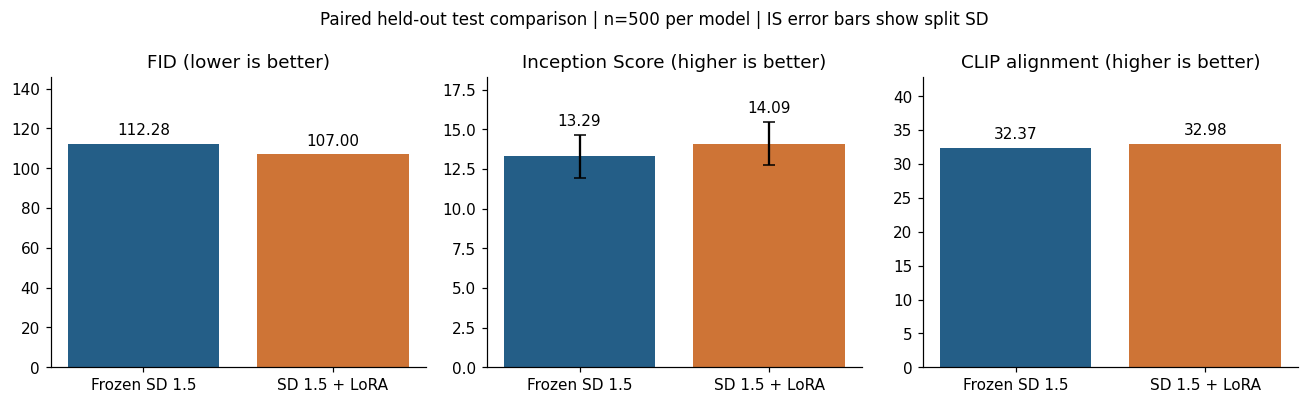

,n,mean_delta,median_delta,positive_fraction,ci_low,ci_high,interval
0,500,0.6141,0.5479,0.606,0.4064,0.8314,95% paired bootstrap over captions; conditiona...


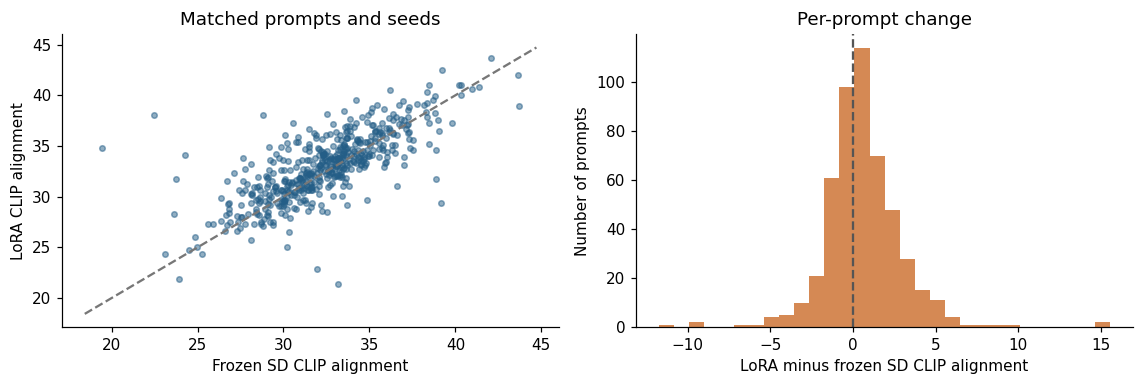

In [10]:
METRICS = ['fid','inception_score_mean','clip_similarity_mean']
LABELS = ['FID (lower is better)','Inception Score (higher is better)','CLIP alignment (higher is better)']
shown = ['run','n_generated','fid','inception_score_mean','inception_score_std',
    'clip_similarity_mean','seconds_per_image','safety_flag_count']
display(test_df[shown].round(4))
baseline_metric = test_df.set_index('run').loc['baseline']
lora_metric = test_df.set_index('run').loc['lora']
model_delta = pd.DataFrame([dict(metric=k,baseline=baseline_metric[k],lora=lora_metric[k],
    absolute_change=lora_metric[k]-baseline_metric[k],
    percent_change=100*(lora_metric[k]/baseline_metric[k]-1)) for k in METRICS+['seconds_per_image']])
model_delta.to_csv(TABLES/'model_deltas.csv',index=False)
display(model_delta.round(4))
fig, axes = plt.subplots(1,3,figsize=(12,3.7))
for ax,metric,label in zip(axes,METRICS,LABELS):
    errors = test_df.inception_score_std if metric == 'inception_score_mean' else None
    bars=ax.bar(['Frozen SD 1.5','SD 1.5 + LoRA'],test_df[metric],color=COLORS[:2],yerr=errors,capsize=4)
    ax.bar_label(bars,fmt='%.2f',padding=4)
    ax.set(title=label,ylim=(0,max(test_df[metric])*1.3))
fig.suptitle(f'Paired held-out test comparison | n={N_TEST} per model | IS error bars show split SD',fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES/'model_comparison.png')
plt.show()

paired_test = test_alignment['baseline'][['id','prompt','clip_similarity']].merge(
    test_alignment['lora'][['id','clip_similarity']],on='id',validate='one_to_one',suffixes=('_baseline','_lora'))
paired_test['delta'] = paired_test.clip_similarity_lora-paired_test.clip_similarity_baseline
paired_test.to_csv(TABLES/'paired_test_alignment.csv',index=False)

def paired_summary(values, seed=42):
    values = np.asarray(values,dtype=float)
    rng = np.random.default_rng(seed)
    means = np.mean(rng.choice(values,size=(2000,len(values)),replace=True),axis=1)
    low,high = np.quantile(means,[.025,.975])
    return dict(n=len(values),mean_delta=float(values.mean()),median_delta=float(np.median(values)),
        positive_fraction=float(np.mean(values>0)),ci_low=float(low),ci_high=float(high),
        interval='95% paired bootstrap over captions; conditional on fixed seeds')

test_paired_summary = paired_summary(paired_test.delta)
pd.DataFrame([test_paired_summary]).to_csv(TABLES/'paired_test_summary.csv',index=False)
display(pd.DataFrame([test_paired_summary]).round(4))
fig,axes = plt.subplots(1,2,figsize=(10.5,3.6))
axes[0].scatter(paired_test.clip_similarity_baseline,paired_test.clip_similarity_lora,s=13,alpha=.5,color=COLORS[0])
limits=[min(paired_test.clip_similarity_baseline.min(),paired_test.clip_similarity_lora.min())-1,
    max(paired_test.clip_similarity_baseline.max(),paired_test.clip_similarity_lora.max())+1]
axes[0].plot(limits,limits,'--',color='#777777')
axes[0].set(xlabel='Frozen SD CLIP alignment',ylabel='LoRA CLIP alignment',title='Matched prompts and seeds')
axes[1].hist(paired_test.delta,bins=30,color=COLORS[1],alpha=.85)
axes[1].axvline(0,color='#555555',linestyle='--')
axes[1].set(xlabel='LoRA minus frozen SD CLIP alignment',ylabel='Number of prompts',title='Per-prompt change')
fig.tight_layout()
fig.savefig(FIGURES/'paired_alignment.png')
plt.show()

,run,n_generated,fid,inception_score_mean,inception_score_std,clip_similarity_mean,seconds_per_image,safety_flag_count
0,baseline,100,227.6894,5.7955,1.1304,32.2513,5.0668,1
1,cfg1,100,251.2563,4.8723,0.6001,27.3506,3.1495,2
2,cfg3,100,222.6348,5.5993,1.0635,31.3766,5.0805,1
3,cfg5,100,222.9551,5.6165,1.0225,31.7072,5.0820,1
4,cfg10,100,227.7551,6.0841,1.1546,32.2045,5.0840,1
5,cfg12,100,226.7044,6.0316,1.2043,32.2978,5.0827,1
6,steps20,100,227.4047,6.0280,1.2686,32.0515,3.4626,1
7,steps50,100,225.3776,6.1292,1.2740,32.0083,8.3181,1
8,euler,100,228.0544,5.7518,1.1144,32.2688,5.0813,1
9,dpm,100,225.3367,5.7271,1.0519,32.1725,5.0782,1


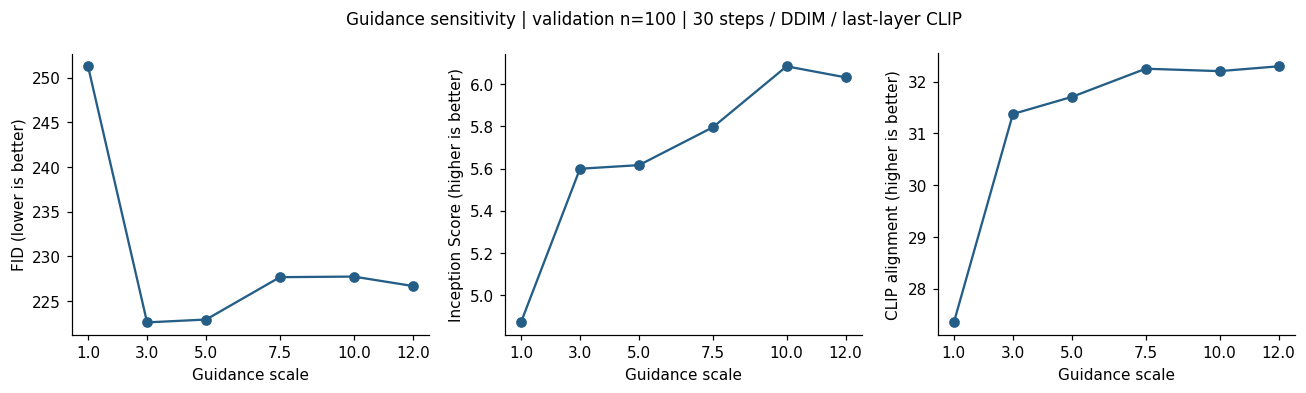

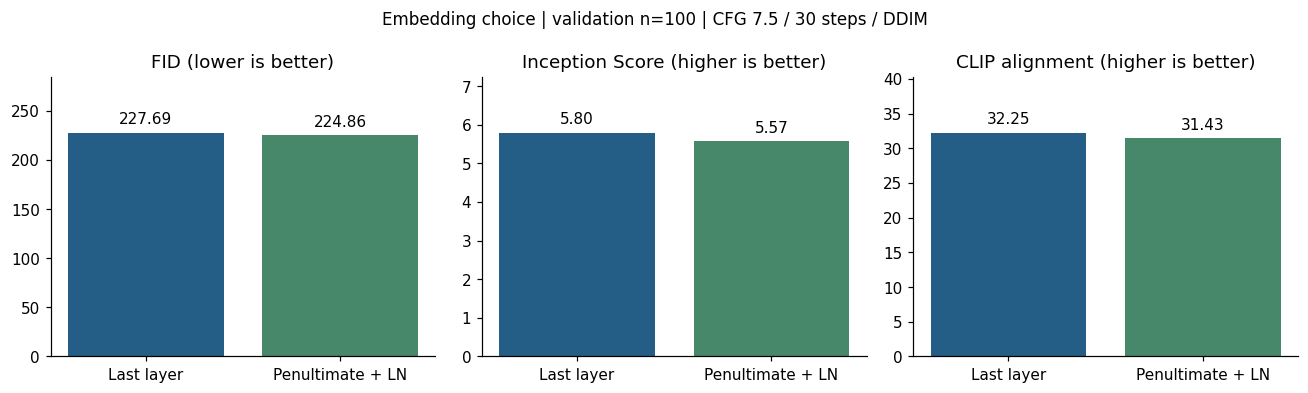

,run,mean_delta,ci_low,ci_high,positive_fraction
0,cfg1,-4.9007,-5.6497,-4.1651,0.07
1,cfg3,-0.8747,-1.3000,-0.4519,0.35
2,cfg5,-0.5441,-0.8529,-0.2536,0.41
3,cfg10,-0.0468,-0.5551,0.3738,0.58
4,cfg12,0.0465,-0.4838,0.4900,0.56
5,steps20,-0.1998,-0.6735,0.1713,0.44
6,steps50,-0.2430,-0.7100,0.1294,0.48
7,euler,0.0176,-0.0196,0.0577,0.51
8,dpm,-0.0788,-0.5512,0.2723,0.53
9,trailing,-0.4113,-0.8797,-0.0606,0.47


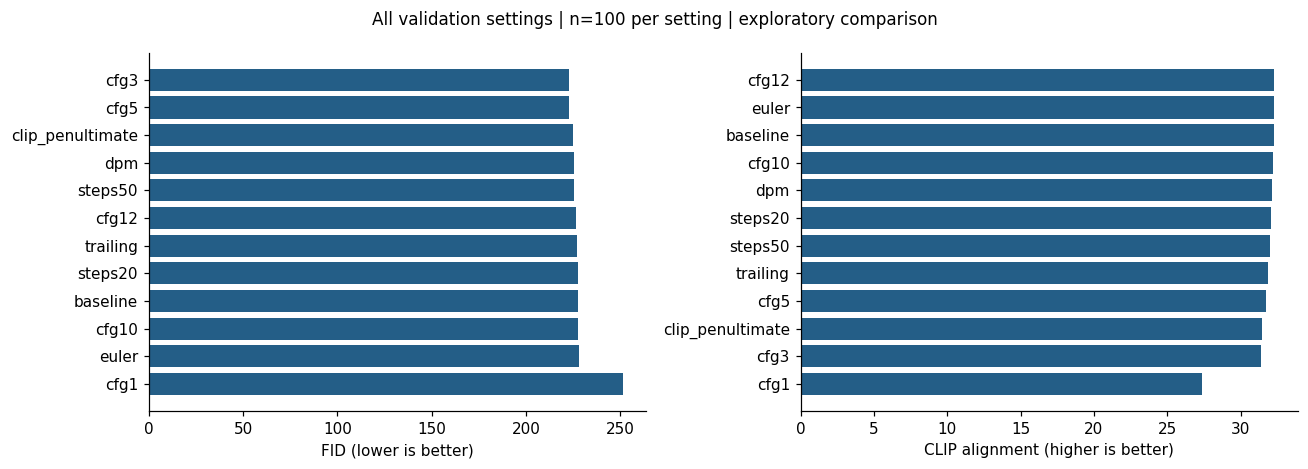

In [11]:
guidance_names = ['cfg1','cfg3','cfg5','baseline','cfg10','cfg12']
guidance_df = validation_df[validation_df.run.isin(guidance_names)].sort_values('guidance').copy()
embedding_df = validation_df[validation_df.run.isin(['baseline','clip_penultimate'])].copy()
guidance_df.to_csv(TABLES/'guidance_sensitivity.csv',index=False)
embedding_df.to_csv(TABLES/'embedding_sensitivity.csv',index=False)
display(validation_df[shown].round(4))
for df,variable,controlled in [(guidance_df,'guidance',['steps','scheduler','spacing','embedding','seed','model','lora']),
        (embedding_df,'embedding',['guidance','steps','scheduler','spacing','seed','model','lora'])]:
    for key in controlled: assert df[key].nunique(dropna=False) == 1,(variable,key)

fig,axes = plt.subplots(1,3,figsize=(12,3.6))
for ax,metric,label in zip(axes,METRICS,LABELS):
    ax.plot(guidance_df.guidance,guidance_df[metric],'o-',color=COLORS[0])
    ax.set(xlabel='Guidance scale',ylabel=label,xticks=guidance_df.guidance)
fig.suptitle(f'Guidance sensitivity | validation n={N_VALIDATION} | 30 steps / DDIM / last-layer CLIP',fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES/'guidance_sensitivity.png')
plt.show()
fig,axes = plt.subplots(1,3,figsize=(12,3.6))
for ax,metric,label in zip(axes,METRICS,LABELS):
    bars=ax.bar(['Last layer','Penultimate + LN'],embedding_df[metric],color=[COLORS[0],COLORS[2]])
    ax.bar_label(bars,fmt='%.2f',padding=4)
    ax.set(title=label,ylim=(0,max(embedding_df[metric])*1.25))
fig.suptitle(f'Embedding choice | validation n={N_VALIDATION} | CFG 7.5 / 30 steps / DDIM',fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES/'embedding_sensitivity.png')
plt.show()

paired_validation = validation_alignment['baseline'][['id','prompt','clip_similarity']].rename(columns={'clip_similarity':'baseline'})
for name,alignment in validation_alignment.items():
    if name != 'baseline':
        paired_validation = paired_validation.merge(alignment[['id','clip_similarity']].rename(columns={'clip_similarity':name}),on='id',validate='one_to_one')
sensitivity_delta = pd.DataFrame([dict(run=name,**paired_summary(paired_validation[name]-paired_validation.baseline))
    for name in validation_alignment if name != 'baseline'])
sensitivity_delta.to_csv(TABLES/'paired_validation_summary.csv',index=False)
paired_validation.to_csv(TABLES/'paired_validation_alignment.csv',index=False)
display(sensitivity_delta[['run','mean_delta','ci_low','ci_high','positive_fraction']].round(4))

fig,axes = plt.subplots(1,2,figsize=(12,4.3))
for ax,metric,label in zip(axes,['fid','clip_similarity_mean'],[LABELS[0],LABELS[2]]):
    ordered=validation_df.sort_values(metric,ascending=metric=='fid')
    ax.barh(ordered.run,ordered[metric],color=COLORS[0])
    ax.invert_yaxis()
    ax.set(xlabel=label)
fig.suptitle(f'All validation settings | n={N_VALIDATION} per setting | exploratory comparison',fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES/'validation_overview.png')
plt.show()

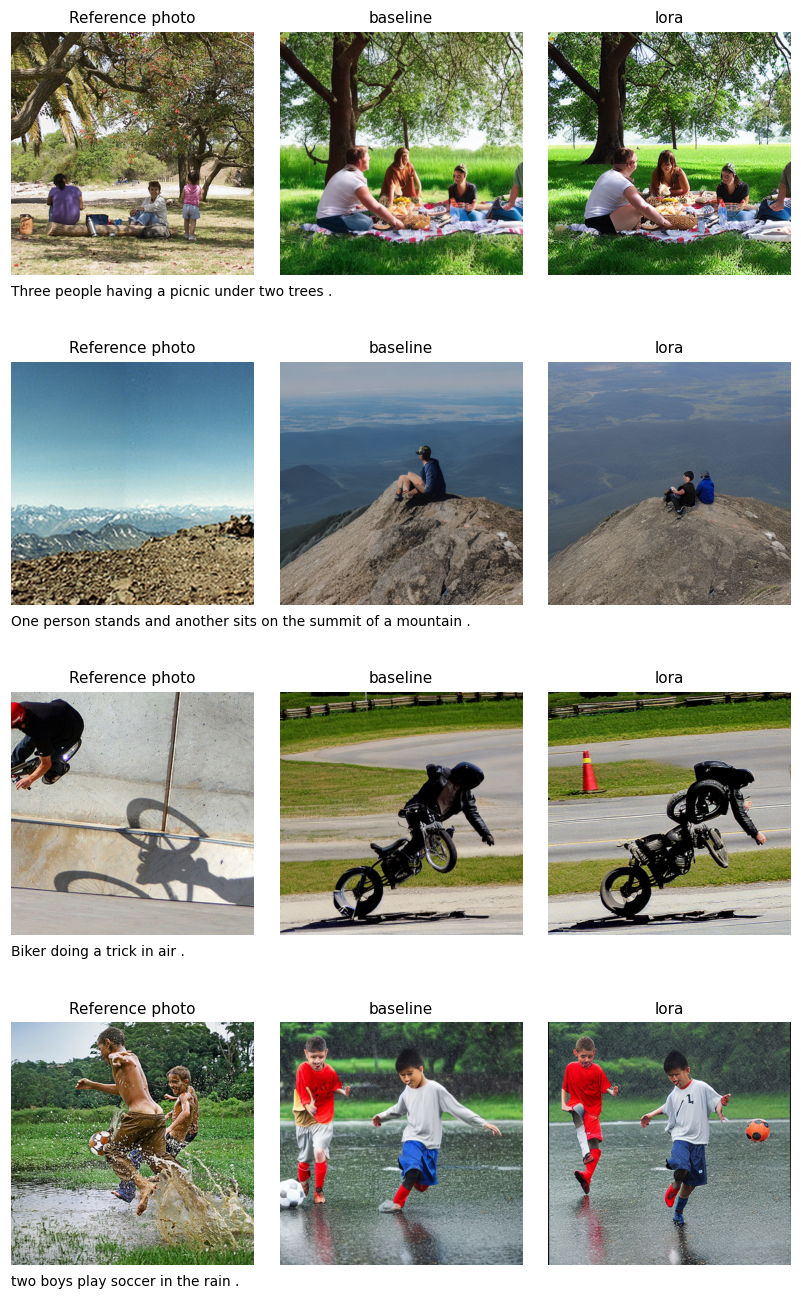

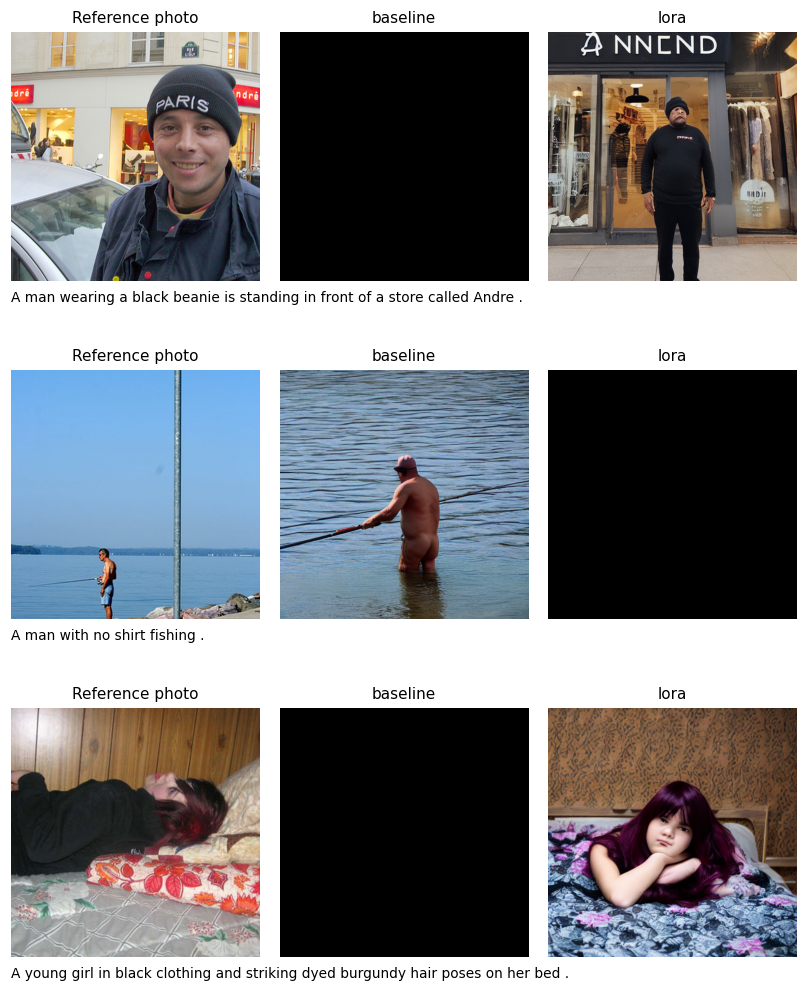

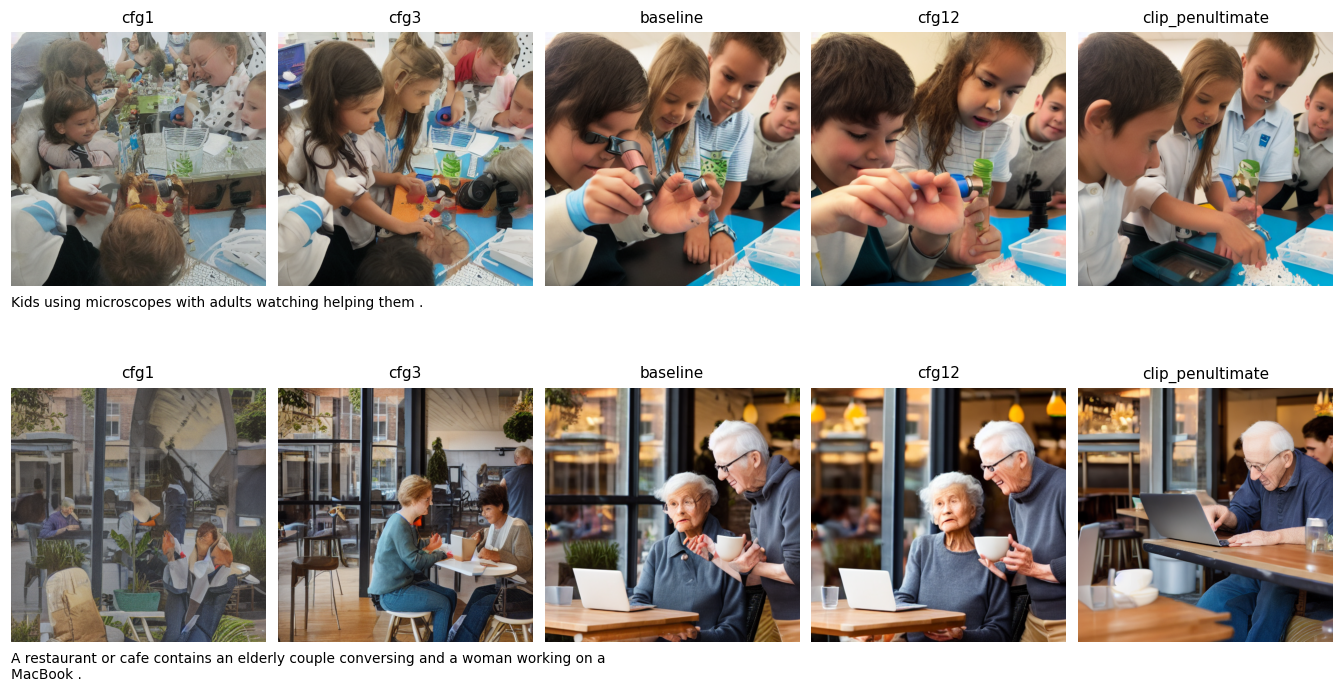

,selection,prompt,clip_delta,alignment_conclusion
0,first four in fixed test order,Three people having a picnic under two trees .,0.909,Pending visual review
1,first four in fixed test order,One person stands and another sits on the summ...,1.536,Pending visual review
2,first four in fixed test order,Biker doing a trick in air .,-0.123,Pending visual review
3,first four in fixed test order,two boys play soccer in the rain .,-0.030,Pending visual review
4,largest CLIP increase,A man wearing a black beanie is standing in fr...,15.586,Pending visual review
5,largest CLIP decrease,A man with no shirt fishing .,-11.759,Pending visual review
6,lowest baseline CLIP,A young girl in black clothing and striking dy...,15.375,Pending visual review


Visual review: inspect sheets and add descriptive notes


In [12]:
test_records = {name:read_jsonl(TEST/name/'manifest.jsonl') for name in ['baseline','lora']}
test_by_id = {name:{r['id']:r for r in rows} for name,rows in test_records.items()}
review_file=NOTEBOOK_DIR/'qualitative_review.json'
review=read_json(review_file) if review_file.exists() else {}
review_valid=(review.get('run_name')==RUN_NAME and review.get('manifest_sha256') ==
    {name:file_hash(TEST/name/'manifest.jsonl') for name in ['baseline','lora']})
omitted={(r['model'],r['id']):r['reason'] for r in review.get('omit_from_figures',[])} if review_valid else {}
fixed_ids = paired_test.id.head(4).tolist()
extra_candidates = [(paired_test.loc[paired_test.delta.idxmax(),'id'],'largest CLIP increase'),
    (paired_test.loc[paired_test.delta.idxmin(),'id'],'largest CLIP decrease'),
    (paired_test.loc[paired_test.clip_similarity_baseline.idxmin(),'id'],'lowest baseline CLIP'),
    (paired_test.loc[paired_test.clip_similarity_lora.idxmin(),'id'],'lowest LoRA CLIP')]
cases = [dict(id=i,selection='first four in fixed test order') for i in fixed_ids]
for image_id,reason in extra_candidates:
    if image_id not in [r['id'] for r in cases]: cases.append(dict(id=image_id,selection=reason))

def comparison_sheet(ids,groups,record_maps,filename,show_reference=False):
    columns = len(groups)+int(show_reference)
    fig,axes=plt.subplots(len(ids),columns,figsize=(3.1*columns,3.15*len(ids)),squeeze=False)
    for i,image_id in enumerate(ids):
        first=record_maps[groups[0]][image_id]
        entries=([('Reference photo',first['reference_image'])] if show_reference else [])
        entries += [(group,record_maps[group][image_id]['image']) for group in groups]
        for j,(label,filename_image) in enumerate(entries):
            if (label,image_id) in omitted:
                axes[i,j].text(.5,.5,omitted[label,image_id],ha='center',va='center',fontsize=11,transform=axes[i,j].transAxes)
                axes[i,j].set_facecolor('#eeeeee')
            else:
                with Image.open(path(filename_image)) as im: axes[i,j].imshow(im.convert('RGB'))
            axes[i,j].axis('off')
            axes[i,j].set_title(label,fontsize=10)
        axes[i,0].text(0,-.04,textwrap.fill(first['prompt'],83),transform=axes[i,0].transAxes,
            ha='left',va='top',fontsize=9)
    fig.subplots_adjust(top=.97,bottom=.08,hspace=.36,wspace=.05)
    fig.savefig(FIGURES/filename,bbox_inches='tight')
    plt.show()

comparison_sheet(fixed_ids,['baseline','lora'],test_by_id,'qualitative_fixed.png',True)
extra_ids=[r['id'] for r in cases if r['id'] not in fixed_ids]
comparison_sheet(extra_ids,['baseline','lora'],test_by_id,'qualitative_diagnostics.png',True)
val_ids=validation_alignment['baseline'].id.head(2).tolist()
val_names=['cfg1','cfg3','baseline','cfg12','clip_penultimate']
val_maps={name:{r['id']:r for r in read_jsonl(SWEEP/name/'manifest.jsonl')} for name in val_names}
comparison_sheet(val_ids,val_names,val_maps,'sensitivity_examples.png')

notes={r['id']:r for r in review.get('cases',[])} if review_valid else {}
case_rows=[]
for case in cases:
    row=paired_test.set_index('id').loc[case['id']]
    note=notes.get(case['id'],{})
    case_rows.append(dict(**case,prompt=row.prompt,baseline_clip=row.clip_similarity_baseline,
        lora_clip=row.clip_similarity_lora,clip_delta=row.delta,
        baseline_observation=note.get('baseline','Pending visual review'),
        lora_observation=note.get('lora','Pending visual review'),
        alignment_conclusion=note.get('conclusion','Pending visual review'),
        review_type='assistant visual inspection' if note else 'pending'))
qualitative_df=pd.DataFrame(case_rows)
qualitative_df.to_csv(TABLES/'qualitative_cases.csv',index=False)
display(qualitative_df[['selection','prompt','clip_delta','alignment_conclusion']].round(3))
for name,alignment in test_alignment.items():
    alignment.to_csv(TABLES/f'alignment_{name}.csv',index=False)
print('Visual review:', 'loaded for this exact experiment' if review_valid else 'inspect sheets and add descriptive notes')